In [7]:
import torch, torchaudio, torch.nn as nn, torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
%%capture
! [ -f names.txt ] || wget https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt

![](lstm_cell_diagram.png)

In [8]:
class LSTM(nn.Module):
	def __init__(self, xdim=64, hdim=64):
		super().__init__()
		# embedding dim, hidden embedding, cell state hidden hyperparameters
		self.xdim, self.hdim = xdim, hdim

		# each W_i for f, i, c, o
		self.W = nn.Linear(xdim, 4*hdim)
		self.U = nn.Linear(hdim, 4*hdim, bias=False)

		self.emb = nn.Embedding(27, xdim)

		self.lm_head = nn.Linear(hdim, 27)
	
	def forward(self, x, c_prev, h_prev):

		z = self.W(self.emb(x)) + self.U(h_prev)
		f, i, cand, o = z.chunk(4, dim=1)
		f, i, cand, o = torch.sigmoid(f), torch.sigmoid(i), torch.tanh(cand), torch.sigmoid(o)

		# cell state, hidden information
		# old + new info
		c = c_prev *f + i*cand
		# squashed memory
		h = o * torch.tanh(c)

		logits = self.lm_head(h)

		return logits, c, h


In [13]:
df = pd.read_csv("names.txt", header=None)
names = df[0].str.lower()
names.shape

(32033,)

In [17]:
mymodel = LSTM()
opt = torch.optim.Adam(mymodel.parameters(), lr=3e-3)

lossi = []

for name in names[:10000]:
	c, h = torch.zeros((1, mymodel.hdim)), torch.zeros((1, mymodel.hdim))
	tokens = [26] + [ord(ch) - ord("a") for ch in name] + [26]

	loss = 0
	for i in range(len(tokens)-1):
		logits, c, h = mymodel(torch.tensor([tokens[i]]), c, h)
		target = tokens[i+1]

		logits = logits - logits.max(dim=1, keepdim=True).values
		cnts = logits.exp() 
		probs = cnts / cnts.sum(dim=1, keepdim=True)

		loss += -probs[0, target].log().mean()
	loss /= len(tokens) - 1

	opt.zero_grad()
	loss.backward()
	opt.step()
	lossi.append(loss.item())


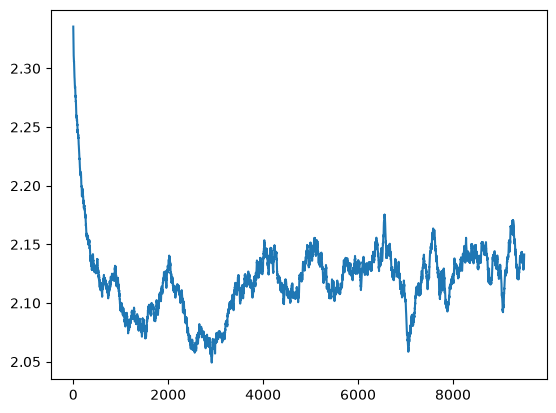

In [18]:
plt.plot(np.convolve(lossi, np.ones(500)/500, mode='valid'))

In [ ]:
for _ in range(10):
	tokens = [26]
	c = torch.zeros(1, mymodel.hdim)
	h = torch.zeros(1, mymodel.hdim)

	while True:
		with torch.no_grad():
			logits, c, h = mymodel(torch.tensor([tokens[-1]]), c, h)

		logits = logits - logits.max(dim=1, keepdim=True).values
		cnts = logits.exp() 
		probs = cnts / cnts.sum(dim=1, keepdim=True)

		cidx = torch.multinomial(probs, num_samples=1, replacement=True).item()
		tokens.append(cidx)

		if cidx == 26:
			break

	name = ""
	for tok in tokens:
		if tok == 26:
			name += "."
		else:
			name += chr(tok + ord("a"))
	print(name)

.bryna.
.vietle.
.tanya.
.malynnn.
.areea.
.fdavana.
.telice.
.nuyza.
.climna.
.yrannla.
